# Pipelines, CI/CD, and Model Drift Monitoring

> Plan checks and monitors around data changes, model behavior, and deployment reliability.

**Track:** Machine Learning Roadmap · **Language:** English

## Learning goals
- Distinguish data drift, concept drift, and performance degradation.
- Calculate simple distribution-shift indicators.
- Define lightweight automated checks for a model pipeline.
- Understand what should be monitored before and after labels arrive.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
rng = np.random.default_rng(2026)
reference = rng.normal(50, 10, 1000)
current = rng.normal(55, 13, 1000)
ks = ks_2samp(reference, current)
summary = pd.DataFrame({"reference": reference, "current": current}).describe().round(2)
display(summary)
print("KS statistic:", round(ks.statistic,3), "p-value:", round(ks.pvalue,5))

KS statistic: 0.166 p-value: 0.0


,reference,current
count,1000.00,1000.00
mean,50.21,53.84
std,10.31,12.70
min,12.53,15.24
25%,43.24,44.75
50%,50.36,53.99
75%,57.11,62.72
max,82.36,98.34


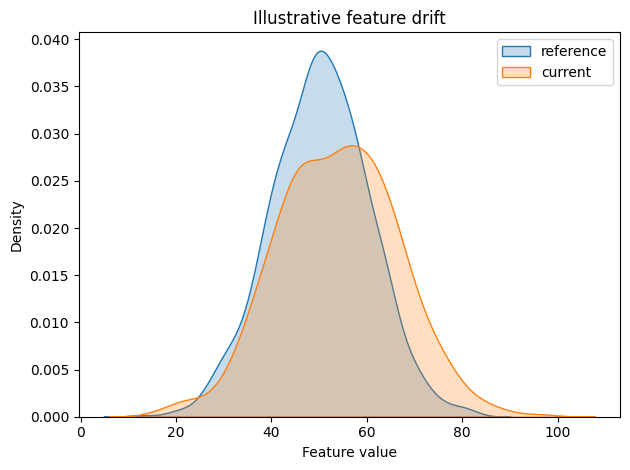

In [2]:
sns.kdeplot(reference, label="reference", fill=True, alpha=.25)
sns.kdeplot(current, label="current", fill=True, alpha=.25)
plt.title("Illustrative feature drift")
plt.xlabel("Feature value")
plt.legend()
plt.tight_layout()

## Drift terminology
- **Data drift:** input feature distribution changes.
- **Concept drift:** relationship between inputs and target changes.
- **Performance degradation:** observed model quality declines; concept drift is one possible cause.

A drift alert does not prove a model is worse. Some shifts are expected seasonality; some are benign changes in volume. Combine statistical signals with domain knowledge, prediction distribution, missingness, latency, and—when labels become available—real model metrics.

In [3]:
# Example of small input validation checks in a pipeline.
def validate_batch(frame, required_columns, numeric_columns):
    missing = sorted(set(required_columns) - set(frame.columns))
    if missing:
        raise ValueError(f"Missing required columns: {missing}")
    if frame[required_columns].isna().any().any():
        raise ValueError("Unexpected missing values in required fields")
    non_numeric = [c for c in numeric_columns if not pd.api.types.is_numeric_dtype(frame[c])]
    if non_numeric:
        raise TypeError(f"Expected numeric columns: {non_numeric}")
    return True
batch = pd.DataFrame({"amount": [12.5, 8.0], "hour": [12, 22]})
print(validate_batch(batch, ["amount", "hour"], ["amount", "hour"]))

True


## CI/CD checks for an ML repository
A useful pull-request workflow can run: formatting/linting, unit tests for feature code, schema checks, a tiny deterministic training smoke test, metric regression bounds, artifact-signature checks, and API contract tests. Do not automatically deploy solely because one offline score increased; require review and rollback criteria.

## Practice
Propose three monitors for a churn model: one input-data monitor, one service monitor, and one model-quality monitor. State how delayed labels change the monitoring design.